# Occlusion-Aware Frame Interpolation with a Learned Blending Mask

**Research prototype for an RTX 3060 Ti (8 GB VRAM).** The optical-flow estimator is frozen; only a small CNN that predicts the blending mask is trained.

## Important methodological notes
- This is an open, DLSS-inspired frame-interpolation experiment, **not NVIDIA DLSS**.
- The midpoint warping below uses a practical half-flow approximation. It is not a full state-of-the-art interpolation pipeline.
- The principal comparison is fixed 50/50 blending vs. a flow-consistency heuristic vs. a learned mask, all using the same flow and warp code.
- Use official Vimeo-90K train/test lists if available. The validation subset is drawn from the official training list; the official test list remains untouched.
- First run the smoke test on a few samples, then scale up.

## 0. Install dependencies

Run this cell in a fresh notebook kernel. If torchvision is already installed with a CUDA-compatible PyTorch, avoid upgrading it blindly; mismatched Torch/torchvision versions can break RAFT.

## 1. Imports, reproducibility, and GPU check

In [42]:
import os, random, time, math, copy, json
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models.optical_flow import raft_small, Raft_Small_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("WARNING: CUDA is unavailable. This project will be much slower.")

# Optional reproducibility setting; strict determinism can reduce speed or reject some CUDA ops.
torch.backends.cudnn.benchmark = True

Device: cuda
GPU: NVIDIA GeForce RTX 3060 Ti
VRAM GB: 8.0


## 2. Configure the locally grouped Vimeo subset

The setup cell groups the source stream's consecutive three-image class-label runs into `vimeo_triplet_grouped/`. It verifies that every listed triplet has `im1.png`, `im2.png`, and `im3.png`; `im2.png` is treated as the target midpoint. The source does not provide a usable official test list or source-video IDs, so all reported test scores are from a local triplet-level holdout.

In [43]:
# %pip -q install datasets pillow

# from datasets import load_dataset
# from pathlib import Path
# from PIL import Image
# from itertools import groupby, islice

# N_TRIPLETS = 1000
# OUT_DIR = Path("./vimeo_triplet_grouped")
# SEQ_DIR = OUT_DIR / "sequences"
# SEQ_DIR.mkdir(parents=True, exist_ok=True)

# # The source stream stores each triplet as three consecutive image rows.
# # Its class label repeats within each triplet; require that structure explicitly.
# ds = load_dataset(
#     "danjacobellis/vimeo90k_triplet",
#     split="train",
#     streaming=True
# )

# def save_triplet(frames, idx):
#     seq_id = idx // 100 + 1
#     item_id = idx % 100 + 1
#     path = SEQ_DIR / f"{seq_id:05d}" / f"{item_id:04d}"
#     path.mkdir(parents=True, exist_ok=True)

#     for frame_index, frame in enumerate(frames, start=1):
#         frame.convert("RGB").save(path / f"im{frame_index}.png")

#     return f"{seq_id:05d}/{item_id:04d}"

# saved_paths = []
# for group_label, group_rows in groupby(ds, key=lambda row: row["label"]):
#     rows = list(islice(group_rows, 4))
#     if len(rows) != 3:
#         raise ValueError(
#             f"Expected exactly 3 consecutive image rows for label {group_label}, got {len(rows)}. "
#             "Do not train until the source dataset grouping is understood."
#         )

#     frames = [row["image"].convert("RGB") for row in rows]
#     if len({frame.tobytes() for frame in frames}) != 3:
#         raise ValueError(f"Duplicate frame found in source triplet with label {group_label}.")

#     saved_paths.append(save_triplet(frames, len(saved_paths)))
#     if len(saved_paths) % 100 == 0:
#         print(f"Saved {len(saved_paths)}/{N_TRIPLETS} grouped triplets")
#     if len(saved_paths) >= N_TRIPLETS:
#         break

# (OUT_DIR / "tri_trainlist.txt").write_text("\n".join(saved_paths) + "\n")
# print(f"\nSaved {len(saved_paths)} grouped triplets under: {OUT_DIR.resolve()}")

In [44]:
from pathlib import Path

DATA_ROOT = Path(r"C:\Users\User\Desktop\Masters\GEn AI\vimeo_triplet_grouped")
SEQUENCES_DIR = DATA_ROOT / "sequences"
TRAIN_LIST = DATA_ROOT / "tri_trainlist.txt"
TEST_LIST = DATA_ROOT / "tri_testlist.txt"

if not SEQUENCES_DIR.is_dir():
    raise FileNotFoundError(f"Vimeo sequences directory not found: {SEQUENCES_DIR}")
if not TRAIN_LIST.is_file():
    raise FileNotFoundError(f"Vimeo training list not found: {TRAIN_LIST}")

local_keys = [line.strip().replace("\\", "/") for line in TRAIN_LIST.read_text().splitlines() if line.strip()]
missing_frames = [
    f"{key}/im{frame}.png"
    for key in local_keys
    for frame in (1, 2, 3)
    if not (SEQUENCES_DIR / key / f"im{frame}.png").is_file()
]
if missing_frames:
    raise FileNotFoundError(f"Missing {len(missing_frames)} frame files; first missing: {missing_frames[:5]}")

N_TRIPLETS = len(local_keys)
print(f"Verified grouped Vimeo subset: {DATA_ROOT}")
print(f"Complete triplets: {N_TRIPLETS}")
print(f"Official test list present: {TEST_LIST.is_file()}")

Verified grouped Vimeo subset: C:\Users\User\Desktop\Masters\GEn AI\vimeo_triplet_grouped
Complete triplets: 1000
Official test list present: False


## 3. Dataset and deterministic split

The source stream exposes image rows and a class label that repeats across three consecutive frames; the setup cell groups those rows into triplets. It does not expose source-video IDs. The generated folder names are storage partitions only, so they are not used as sequence groups for splitting. Because no official test list or source-video IDs are available, the notebook makes a deterministic triplet-level train/validation/test holdout. Treat results as a small local-subset experiment, not an official or video-leakage-controlled benchmark.

In [45]:
def read_list(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing list file: {path}")
    return [line.strip().replace("\\", "/") for line in path.read_text().splitlines() if line.strip()]

class VimeoTriplets(Dataset):
    def __init__(self, sequences_dir, keys, crop_size=None, augment=False):
        self.sequences_dir = Path(sequences_dir)
        self.keys = list(keys)
        self.crop_size = crop_size
        self.augment = augment

    def __len__(self):
        return len(self.keys)

    def _load_rgb(self, path):
        im = Image.open(path).convert("RGB")
        arr = np.asarray(im, dtype=np.uint8).copy()
        return torch.from_numpy(arr).permute(2, 0, 1).float() / 255.0

    def __getitem__(self, idx):
        key = self.keys[idx]
        folder = self.sequences_dir / key
        frames = [self._load_rgb(folder / f"im{i}.png") for i in (1, 2, 3)]
        a, target, b = frames

        if self.crop_size is not None:
            _, h, w = a.shape
            ch = min(self.crop_size, h)
            cw = min(self.crop_size, w)
            top = random.randint(0, h - ch)
            left = random.randint(0, w - cw)
            a = a[:, top:top+ch, left:left+cw]
            target = target[:, top:top+ch, left:left+cw]
            b = b[:, top:top+ch, left:left+cw]

        if self.augment:
            if random.random() < 0.5:
                a, target, b = [x.flip(-1) for x in (a, target, b)]
            if random.random() < 0.5:
                a, target, b = [x.flip(-2) for x in (a, target, b)]
            if random.random() < 0.5:
                a, b = b, a

        return a, target, b, key

def make_splits(val_fraction=0.15, test_fraction=0.15, max_train=None, max_val=None, max_test=None):
    all_keys = read_list(TRAIN_LIST)
    rng = random.Random(SEED)
    rng.shuffle(all_keys)

    n_test = max(1, int(len(all_keys) * test_fraction))
    n_val = max(1, int(len(all_keys) * val_fraction))
    if n_test + n_val >= len(all_keys):
        raise ValueError("Not enough triplets for non-empty train, validation, and test splits.")

    test_keys = all_keys[:n_test]
    val_keys = all_keys[n_test:n_test + n_val]
    train_keys = all_keys[n_test + n_val:]
    split_source = "local triplet holdout (source-video IDs unavailable)"

    if max_train is not None: train_keys = train_keys[:max_train]
    if max_val is not None: val_keys = val_keys[:max_val]
    if max_test is not None: test_keys = test_keys[:max_test]

    assert not (set(train_keys) & set(val_keys))
    assert not (set(train_keys) & set(test_keys))
    assert not (set(val_keys) & set(test_keys))
    return train_keys, val_keys, test_keys, split_source

TRAIN_LIMIT = 10_000
VAL_LIMIT = 1_000
TEST_LIMIT = 1_000

if SEQUENCES_DIR.exists() and TRAIN_LIST.exists():
    train_keys, val_keys, test_keys, split_source = make_splits(
        val_fraction=0.15,
        test_fraction=0.15,
        max_train=TRAIN_LIMIT, max_val=VAL_LIMIT, max_test=TEST_LIMIT
    )
    print(f"Split source: {split_source}")
    print(f"Train: {len(train_keys)} | validation: {len(val_keys)} | test: {len(test_keys)}")
else:
    train_keys, val_keys, test_keys = [], [], []
    print("Run the local Vimeo setup cell and verify DATA_ROOT before creating datasets.")

Split source: local triplet holdout (source-video IDs unavailable)
Train: 700 | validation: 150 | test: 150


## 4. Load the frozen RAFT-small model

Torchvision RAFT expects inputs normalized by its weights transform. Inputs are resized only if needed to satisfy the model's divisibility requirements; output flow is resized back to the original image dimensions and scaled in pixel units.

In [46]:
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

FLOW_WEIGHTS = Raft_Small_Weights.DEFAULT
flow_model = raft_small(weights=FLOW_WEIGHTS, progress=True).to(DEVICE).eval()
for p in flow_model.parameters():
    p.requires_grad_(False)

flow_preprocess = FLOW_WEIGHTS.transforms()

@torch.no_grad()
def estimate_flow(img_a, img_b):
    # img_a/img_b: [B,3,H,W] float in [0,1]
    B, C, H, W = img_a.shape
    # RAFT implementation requires dimensions divisible by 8.
    h8, w8 = (H // 8) * 8, (W // 8) * 8
    if h8 < 8 or w8 < 8:
        raise ValueError("Input spatial dimensions must be at least 8x8.")
    a = F.interpolate(img_a, size=(h8, w8), mode="bilinear", align_corners=False)
    b = F.interpolate(img_b, size=(h8, w8), mode="bilinear", align_corners=False)
    a, b = flow_preprocess(a, b)
    flow = flow_model(a, b)[-1]
    flow = F.interpolate(flow, size=(H, W), mode="bilinear", align_corners=False)
    flow[:, 0] *= W / w8
    flow[:, 1] *= H / h8
    return flow

print("RAFT-small loaded and frozen.")

RAFT-small loaded and frozen.


## 5. Midpoint warping and baseline masks

`grid_sample` uses a backward sampling grid. We approximate the midpoint warp using half of the flow from each endpoint. This is intentionally a simple, transparent baseline; it is not equivalent to a specialized frame interpolation model with learned flow refinement.

For endpoint flows `f01` and `f10`, we approximate:
- `W0 = warp(I0, -0.5 * f01)`
- `W1 = warp(I1, -0.5 * f10)`

The heuristic mask uses forward/backward flow consistency as a rough visibility cue. This is a baseline, not ground-truth occlusion supervision.

In [47]:
def flow_warp(image, flow):
    # image: [B,C,H,W], flow: [B,2,H,W] in pixel units.
    B, C, H, W = image.shape
    yy, xx = torch.meshgrid(
        torch.arange(H, device=image.device, dtype=image.dtype),
        torch.arange(W, device=image.device, dtype=image.dtype),
        indexing="ij"
    )
    base = torch.stack((xx, yy), dim=0).unsqueeze(0).expand(B, -1, -1, -1)
    coords = base + flow
    gx = 2.0 * coords[:, 0] / max(W - 1, 1) - 1.0
    gy = 2.0 * coords[:, 1] / max(H - 1, 1) - 1.0
    grid = torch.stack((gx, gy), dim=-1)
    return F.grid_sample(image, grid, mode="bilinear", padding_mode="border", align_corners=True)

@torch.no_grad()
def make_warps(a, b):
    f01 = estimate_flow(a, b)
    f10 = estimate_flow(b, a)
    w0 = flow_warp(a, -0.5 * f01)
    w1 = flow_warp(b, -0.5 * f10)
    return w0, w1, f01, f10

def fixed_blend(w0, w1):
    return 0.5 * w0 + 0.5 * w1

def heuristic_mask(w0, w1, f01, f10):
    # Approximate forward/backward consistency at the endpoint grids.
    # Warp f10 into frame-0 coordinates and f01 into frame-1 coordinates.
    f10_at_0 = flow_warp(f10, f01)
    f01_at_1 = flow_warp(f01, f10)
    e0 = torch.linalg.vector_norm(f01 + f10_at_0, dim=1, keepdim=True)
    e1 = torch.linalg.vector_norm(f10 + f01_at_1, dim=1, keepdim=True)
    # Lower consistency error => higher confidence. Soft weights avoid hard seams.
    c0 = torch.exp(-e0 / 2.0)
    c1 = torch.exp(-e1 / 2.0)
    return c0 / (c0 + c1 + 1e-6)

def apply_mask(w0, w1, mask):
    return mask * w0 + (1.0 - mask) * w1

## 6. Small trainable mask CNN

Input channels: warped frame 0 (3), warped frame 1 (3), absolute difference (3), and two flow magnitudes (2) = 11 channels. The CNN predicts a one-channel mask with sigmoid activation. Optical flow is computed without gradient tracking; only the mask CNN receives gradients.

In [48]:
class MaskCNN(nn.Module):
    def __init__(self, in_channels=11, width=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, width, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(width, width // 2, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(width // 2, 1, 3, padding=1),
        )
        for layer in self.net:
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)
        nn.init.xavier_normal_(self.net[-1].weight, gain=0.1)

    def forward(self, x):
        return torch.sigmoid(self.net(x))

def make_mask_features(w0, w1, f01, f10):
    m01 = torch.linalg.vector_norm(f01, dim=1, keepdim=True)
    m10 = torch.linalg.vector_norm(f10, dim=1, keepdim=True)
    scale = max(w0.shape[-2:]) / 10.0
    m01 = m01 / max(scale, 1.0)
    m10 = m10 / max(scale, 1.0)
    return torch.cat([w0, w1, (w0-w1).abs(), m01, m10], dim=1)

mask_model = MaskCNN().to(DEVICE)
optimizer = torch.optim.AdamW(
    mask_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
print("Trainable parameters:", sum(p.numel() for p in mask_model.parameters() if p.requires_grad))

Trainable parameters: 26465


## 7. Data loaders and smoke test

Start with a small number of triplets and one epoch to verify paths, flow estimation, tensor shapes, and GPU memory before scaling up.

In [49]:
if len(train_keys) > 0:
    train_ds = VimeoTriplets(SEQUENCES_DIR, train_keys, crop_size=128, augment=True)
    val_ds = VimeoTriplets(SEQUENCES_DIR, val_keys, crop_size=None, augment=False)
    test_ds = VimeoTriplets(SEQUENCES_DIR, test_keys, crop_size=None, augment=False)

    # Zero workers is the most reliable default for notebook execution on Windows.
    NUM_WORKERS = 0
    train_loader = DataLoader(train_ds, batch_size=6, shuffle=True, num_workers=NUM_WORKERS,
                              pin_memory=(DEVICE.type=="cuda"), drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=2, shuffle=False, num_workers=NUM_WORKERS,
                            pin_memory=(DEVICE.type=="cuda"))
    test_loader = DataLoader(test_ds, batch_size=2, shuffle=False, num_workers=NUM_WORKERS,
                             pin_memory=(DEVICE.type=="cuda"))

    sample = train_ds[0]
    print("Loaders ready.")
    print("Sample:", sample[3], "| frame tensor shapes:", [tuple(frame.shape) for frame in sample[:3]])
else:
    print("Run the local Vimeo setup and split cells before creating datasets.")

Loaders ready.
Sample: 00001/0032 | frame tensor shapes: [(3, 128, 128), (3, 128, 128), (3, 128, 128)]


## 8. Training and validation

Train the blending mask with pixel-wise MSE, which directly matches the PSNR validation objective. The target frame is never passed into the flow estimator or mask network; it is used only to calculate the training loss. Existing outputs from the earlier overlapping-window dataset are stale; rerun the updated cells from the local dataset setup through training in order.

In [59]:
def run_train_epoch(loader):
    mask_model.train()
    losses = []
    mask_means = []
    mask_stds = []
    pbar = tqdm(loader, desc="train", leave=False)
    for a, target, b, _keys in pbar:
        a = a.to(DEVICE, non_blocking=True)
        target = target.to(DEVICE, non_blocking=True)
        b = b.to(DEVICE, non_blocking=True)

        with torch.no_grad():
            w0, w1, f01, f10 = make_warps(a, b)
            features = make_mask_features(w0, w1, f01, f10)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE.type=="cuda")):
            mask = mask_model(features)
            pred = apply_mask(w0, w1, mask)
            loss = F.mse_loss(pred, target)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.item())
        mask_means.append(mask.detach().mean().item())
        mask_stds.append(mask.detach().std().item())
        pbar.set_postfix(mse=f"{np.mean(losses):.6f}", mask=f"{np.mean(mask_means):.3f}")
    if not losses:
        return float("nan"), float("nan"), float("nan")
    return float(np.mean(losses)), float(np.mean(mask_means)), float(np.mean(mask_stds))

@torch.inference_mode()
def validate(loader, max_batches=None):
    mask_model.eval()
    rows = []
    for batch_index, (a, target, b, keys) in enumerate(tqdm(loader, desc="val", leave=False)):
        if max_batches is not None and batch_index >= max_batches:
            break
        a = a.to(DEVICE)
        target = target.to(DEVICE)
        b = b.to(DEVICE)
        w0, w1, f01, f10 = make_warps(a, b)
        pred_fixed = fixed_blend(w0, w1)
        pred_heur = apply_mask(w0, w1, heuristic_mask(w0, w1, f01, f10))
        learned_mask = mask_model(make_mask_features(w0, w1, f01, f10))
        pred_learned = apply_mask(w0, w1, learned_mask)

        for sample_index, key in enumerate(keys):
            target_sample = target[sample_index:sample_index + 1]

            def metrics(pred):
                pred = pred[sample_index:sample_index + 1].clamp(0, 1)
                mse = F.mse_loss(pred, target_sample).item()
                psnr = -10 * math.log10(max(mse, 1e-12))
                x, y = pred, target_sample
                mu_x, mu_y = x.mean(), y.mean()
                var_x, var_y = x.var(unbiased=False), y.var(unbiased=False)
                cov = ((x-mu_x)*(y-mu_y)).mean()
                c1, c2 = 0.01**2, 0.03**2
                ssim = ((2*mu_x*mu_y+c1)*(2*cov+c2))/((mu_x**2+mu_y**2+c1)*(var_x+var_y+c2)+1e-12)
                return psnr, float(ssim.item()), float((pred-y).abs().mean().item())

            for name, pred in [("fixed", pred_fixed), ("heuristic", pred_heur), ("learned", pred_learned)]:
                psnr, ssim, l1 = metrics(pred)
                rows.append({"key": key, "method": name, "psnr": psnr, "ssim_global": ssim, "l1": l1})
            rows[-1]["mask_mean"] = float(learned_mask[sample_index].mean().item())
            rows[-1]["mask_std"] = float(learned_mask[sample_index].std().item())
    return pd.DataFrame(rows)

# Quick shape check before the dedicated gradient smoke test.
if len(train_keys) > 0:
    a, target, b, _ = next(iter(train_loader))
    a, target, b = a.to(DEVICE), target.to(DEVICE), b.to(DEVICE)
    with torch.no_grad():
        w0, w1, f01, f10 = make_warps(a, b)
        feat = make_mask_features(w0, w1, f01, f10)
        out = apply_mask(w0, w1, mask_model(feat))
    print("Input:", tuple(a.shape), "Features:", tuple(feat.shape), "Output:", tuple(out.shape))

Input: (6, 3, 128, 128) Features: (6, 11, 128, 128) Output: (6, 3, 128, 128)


In [51]:
if len(train_keys) > 0:
    a, target, b, _ = next(iter(train_loader))
    a, target, b = a.to(DEVICE), target.to(DEVICE), b.to(DEVICE)

    with torch.no_grad():
        w0, w1, f01, f10 = make_warps(a, b)
        features = make_mask_features(w0, w1, f01, f10)

    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
        smoke_mask = mask_model(features)
        pred = apply_mask(w0, w1, smoke_mask)
        smoke_loss = F.mse_loss(pred, target)
    smoke_loss.backward()
    grad_norm = torch.sqrt(sum(parameter.grad.detach().float().pow(2).sum()
                               for parameter in mask_model.parameters() if parameter.grad is not None))
    optimizer.zero_grad(set_to_none=True)

    if not torch.isfinite(grad_norm) or grad_norm.item() == 0:
        raise RuntimeError("Gradient smoke test failed: mask CNN gradients are missing or non-finite.")
    print(f"Gradient smoke test passed. MSE={smoke_loss.item():.6f}, "
          f"grad norm={grad_norm.item():.4f}, mask mean/std="
          f"{smoke_mask.mean().item():.3f}/{smoke_mask.std().item():.3f}")

Gradient smoke test passed. MSE=0.002396, grad norm=0.0003, mask mean/std=0.509/0.004


In [52]:
# Validation-driven training: stop if the local holdout does not improve.
MAX_EPOCHS = 20
EARLY_STOP_PATIENCE = 5
MIN_PSNR_GAIN = 0.01
BEST_PSNR = -float("inf")
EPOCHS_WITHOUT_IMPROVEMENT = 0
history = []
CHECKPOINT_PATH = Path("mask_cnn_best.pt")
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2,
    threshold=MIN_PSNR_GAIN, threshold_mode="abs"
)

if len(train_keys) > 0:
    for epoch in range(1, MAX_EPOCHS + 1):
        train_mse, train_mask_mean, train_mask_std = run_train_epoch(train_loader)
        val_df = validate(val_loader, max_batches=None)
        learned_rows = val_df[val_df.method == "learned"]
        learned_psnr = float(learned_rows.psnr.mean())
        fixed_psnr = float(val_df.loc[val_df.method == "fixed", "psnr"].mean())
        val_mask_mean = float(learned_rows.mask_mean.mean())
        val_mask_std = float(learned_rows.mask_std.mean())
        scheduler.step(learned_psnr)
        current_lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            "train_mse": train_mse,
            "train_mask_mean": train_mask_mean,
            "train_mask_std": train_mask_std,
            "val_learned_psnr": learned_psnr,
            "val_fixed_psnr": fixed_psnr,
            "val_mask_mean": val_mask_mean,
            "val_mask_std": val_mask_std,
            "lr": current_lr,
        })
        print(
            f"Epoch {epoch:02d} | train MSE={train_mse:.6f} | "
            f"val learned/fixed PSNR={learned_psnr:.3f}/{fixed_psnr:.3f} | "
            f"mask mean/std={val_mask_mean:.3f}/{val_mask_std:.3f} | lr={current_lr:.2g}"
        )

        if learned_psnr > BEST_PSNR + MIN_PSNR_GAIN:
            BEST_PSNR = learned_psnr
            EPOCHS_WITHOUT_IMPROVEMENT = 0
            torch.save({
                "model": mask_model.state_dict(),
                "epoch": int(epoch),
                "val_psnr": float(learned_psnr),
                "seed": int(SEED),
            }, CHECKPOINT_PATH)
        else:
            EPOCHS_WITHOUT_IMPROVEMENT += 1
            if EPOCHS_WITHOUT_IMPROVEMENT >= EARLY_STOP_PATIENCE:
                print(f"Early stopping after {epoch} epochs; no meaningful validation gain.")
                break

    history_df = pd.DataFrame(history)
    display(history_df)
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
    mask_model.load_state_dict(checkpoint["model"])
    print(f"Restored best checkpoint from epoch {checkpoint['epoch']} (PSNR={checkpoint['val_psnr']:.3f}).")
else:
    print("Configure dataset paths first.")

Epoch 01 | train MSE=0.001243 | val learned/fixed PSNR=31.529/31.526 | mask mean/std=0.497/0.001 | lr=0.001


Epoch 02 | train MSE=0.001190 | val learned/fixed PSNR=31.528/31.526 | mask mean/std=0.497/0.001 | lr=0.001


Epoch 03 | train MSE=0.001184 | val learned/fixed PSNR=31.490/31.526 | mask mean/std=0.506/0.003 | lr=0.001


Epoch 04 | train MSE=0.001239 | val learned/fixed PSNR=31.541/31.526 | mask mean/std=0.499/0.002 | lr=0.001


Epoch 05 | train MSE=0.001120 | val learned/fixed PSNR=31.520/31.526 | mask mean/std=0.501/0.001 | lr=0.001


...

Epoch 07 | train MSE=0.001220 | val learned/fixed PSNR=31.537/31.526 | mask mean/std=0.498/0.003 | lr=0.0005


Epoch 08 | train MSE=0.001150 | val learned/fixed PSNR=31.538/31.526 | mask mean/std=0.500/0.001 | lr=0.0005


Epoch 09 | train MSE=0.001153 | val learned/fixed PSNR=31.526/31.526 | mask mean/std=0.504/0.000 | lr=0.0005
Early stopping after 9 epochs; no meaningful validation gain.


,epoch,train_mse,train_mask_mean,train_mask_std,val_learned_psnr,val_fixed_psnr,val_mask_mean,val_mask_std,lr
0,1,0.001243,0.504948,0.005605,31.528969,31.525972,0.496991,0.001032,0.0010
1,2,0.001190,0.491019,0.012036,31.528077,31.525972,0.497247,0.001247,0.0010
2,3,0.001184,0.490327,0.017101,31.489942,31.525972,0.505654,0.003128,0.0010
3,4,0.001239,0.504498,0.008581,31.540854,31.525972,0.498952,0.002446,0.0010
4,5,0.001120,0.506849,0.018662,31.520042,31.525972,0.500603,0.000594,0.0010
5,6,0.001251,0.506438,0.016743,31.527171,31.525972,0.499219,0.000253,0.0010
6,7,0.001220,0.498299,0.016944,31.536788,31.525972,0.497771,0.002570,0.0005
7,8,0.001150,0.490129,0.016152,31.538238,31.525972,0.500276,0.001043,0.0005
8,9,0.001153,0.498539,0.010864,31.525623,31.525972,0.504337,0.000388,0.0005


Restored best checkpoint from epoch 4 (PSNR=31.541).


## 9. Final test evaluation

Run this only after model selection is complete. With the provided local subset, this evaluates the deterministic local test holdout, not the official Vimeo-90K test set. Do not tune hyperparameters based on these results. For an official benchmark, provide the official held-out test list and keep it untouched.

For final reporting, calculate SSIM using `skimage.metrics.structural_similarity` on each RGB image. The quick validation helper above reports a global SSIM approximation for fast checks; do not present that approximation as the standard benchmark SSIM.

In [60]:
from skimage.metrics import structural_similarity

@torch.inference_mode()
def standard_metrics(pred, target):
    pred_np = pred[0].clamp(0,1).permute(1,2,0).detach().cpu().numpy()
    tgt_np = target[0].clamp(0,1).permute(1,2,0).detach().cpu().numpy()
    mse = float(np.mean((pred_np - tgt_np) ** 2))
    psnr = -10 * np.log10(max(mse, 1e-12))
    ssim = structural_similarity(tgt_np, pred_np, channel_axis=2, data_range=1.0)
    l1 = float(np.mean(np.abs(pred_np - tgt_np)))
    return psnr, float(ssim), l1

@torch.inference_mode()
def evaluate_test(loader, max_batches=None):
    mask_model.eval()
    rows = []
    for batch_index, (a, target, b, keys) in enumerate(tqdm(loader, desc="test")):
        if max_batches is not None and batch_index >= max_batches:
            break
        a, target, b = a.to(DEVICE), target.to(DEVICE), b.to(DEVICE)
        w0, w1, f01, f10 = make_warps(a, b)
        preds = {
            "fixed": fixed_blend(w0, w1),
            "heuristic": apply_mask(w0, w1, heuristic_mask(w0, w1, f01, f10)),
            "learned": apply_mask(w0, w1, mask_model(make_mask_features(w0, w1, f01, f10))),
        }
        for sample_index, key in enumerate(keys):
            for method, pred in preds.items():
                psnr, ssim, l1 = standard_metrics(
                    pred[sample_index:sample_index + 1],
                    target[sample_index:sample_index + 1]
                )
                rows.append({"key": key, "method": method, "psnr": psnr, "ssim": ssim, "l1": l1})
    return pd.DataFrame(rows)

if len(test_keys) > 0:
    test_results = evaluate_test(test_loader, max_batches=None)
    display(test_results.groupby("method")[["psnr", "ssim", "l1"]].agg(["mean", "median", "std"]))
    test_results.to_csv("test_metrics_per_triplet.csv", index=False)
else:
    print("Configure dataset paths and loaders first.")

test: 100%|██████████| 75/75 [00:09<00:00,  7.95it/s]


psnr                           ssim                      \
                mean     median       std      mean    median       std   
method                                                                    
fixed      33.062795  32.996620  4.742686  0.947630  0.954200  0.031548   
heuristic  32.677510  32.569557  4.904664  0.946563  0.953190  0.032324   
learned    33.070529  33.031044  4.738487  0.947666  0.954194  0.031521   

                 l1                      
               mean    median       std  
method                                   
fixed      0.011666  0.010226  0.006442  
heuristic  0.011843  0.010189  0.006586  
learned    0.011660  0.010227  0.006439

## 10. Qualitative visualization

Inspect the same held-out triplet across methods. Look especially at moving boundaries, disocclusions, thin structures, and fast motion.

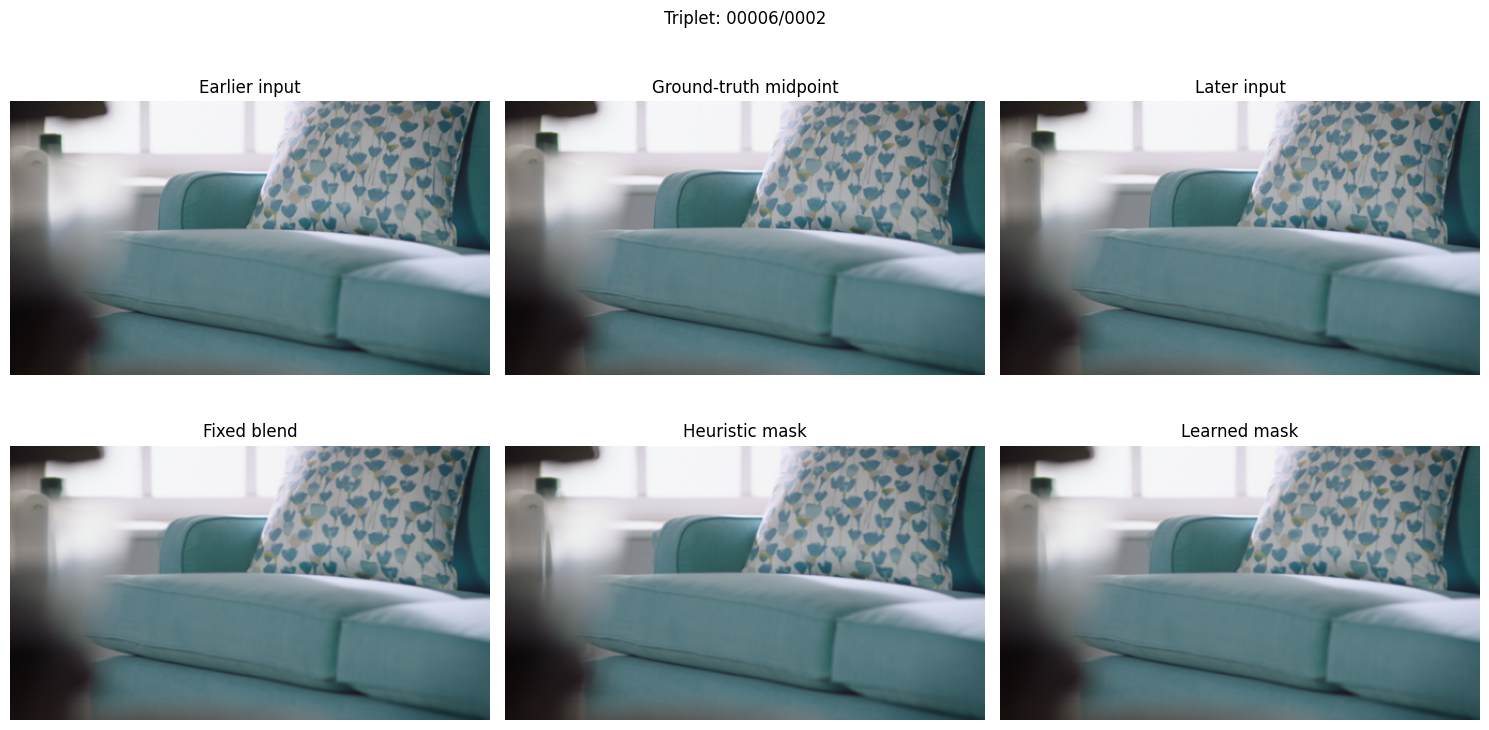

In [54]:
@torch.inference_mode()
def show_triplet(dataset, index=0):
    mask_model.eval()
    a, target, b, key = dataset[index]
    a, target, b = [x.unsqueeze(0).to(DEVICE) for x in (a, target, b)]
    w0, w1, f01, f10 = make_warps(a, b)
    preds = {
        "Earlier input": a,
        "Ground-truth midpoint": target,
        "Later input": b,
        "Fixed blend": fixed_blend(w0, w1),
        "Heuristic mask": apply_mask(w0, w1, heuristic_mask(w0, w1, f01, f10)),
        "Learned mask": apply_mask(w0, w1, mask_model(make_mask_features(w0, w1, f01, f10))),
    }
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (title, img) in zip(axes.flat, preds.items()):
        ax.imshow(img[0].clamp(0,1).permute(1,2,0).cpu().numpy())
        ax.set_title(title)
        ax.axis("off")
    plt.suptitle(f"Triplet: {key}")
    plt.tight_layout()
    plt.show()

if len(test_keys) > 0:
    show_triplet(test_ds, index=15)

## 11. Latency benchmark

Report both the learned mask's incremental cost and the full pipeline cost. The latter includes two RAFT passes and warping. Use batch size 1 and the exact resolution in the report.

In [55]:
@torch.inference_mode()
def benchmark_one_pair(a, b, warmup=5, repeats=20):
    a, b = a.unsqueeze(0).to(DEVICE), b.unsqueeze(0).to(DEVICE)
    for _ in range(warmup):
        w0, w1, f01, f10 = make_warps(a, b)
        features = make_mask_features(w0, w1, f01, f10)
        _ = mask_model(features)
    if DEVICE.type == "cuda": torch.cuda.synchronize()

    t0 = time.perf_counter()
    for _ in range(repeats):
        w0, w1, f01, f10 = make_warps(a, b)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    flow_ms = (time.perf_counter()-t0)*1000/repeats

    features = make_mask_features(w0, w1, f01, f10)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(repeats):
        _ = mask_model(features)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    mask_ms = (time.perf_counter()-t0)*1000/repeats
    return {"flow_and_warp_ms": flow_ms, "mask_cnn_ms": mask_ms,
            "approx_total_ms": flow_ms+mask_ms, "resolution": tuple(a.shape[-2:])}

if len(test_keys) > 0:
    a, target, b, _ = test_ds[0]
    print(benchmark_one_pair(a, b))

{'flow_and_warp_ms': 34.14284000173211, 'mask_cnn_ms': 1.1497450002934784, 'approx_total_ms': 35.29258500202559, 'resolution': (256, 448)}


## 12. Optional: save an interpolated video from your own clip

This is a demo utility, not part of the benchmark. It reads a video, resizes frames to a manageable resolution, and inserts one generated midpoint between adjacent frames. It can be slow because RAFT is called twice per pair. Test on a 2–5 second clip first.

Install `opencv-python` if needed. For a fair visual comparison, render the same source frames with fixed and learned masks.

In [56]:
# Uncomment and edit paths if you want a demo from a local video.
# %pip install -q opencv-python
#
# import cv2
#
# def generate_interpolated_video(input_path, output_path, max_width=640, fps_override=None):
#     cap = cv2.VideoCapture(str(input_path))
#     fps = fps_override or cap.get(cv2.CAP_PROP_FPS) or 25.0
#     frames = []
#     while True:
#         ok, bgr = cap.read()
#         if not ok: break
#         h, w = bgr.shape[:2]
#         if w > max_width:
#             new_h = int(h * max_width / w)
#             bgr = cv2.resize(bgr, (max_width, new_h), interpolation=cv2.INTER_AREA)
#         rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
#         frames.append(torch.from_numpy(rgb.copy()).permute(2,0,1).float()/255.)
#     cap.release()
#     if len(frames) < 2: raise ValueError("Video needs at least two frames.")
#     h, w = frames[0].shape[-2:]
#     writer = cv2.VideoWriter(str(output_path), cv2.VideoWriter_fourcc(*"mp4v"), fps*2, (w,h))
#     mask_model.eval()
#     with torch.inference_mode():
#         for i in tqdm(range(len(frames)-1), desc="Generating"):
#             a, b = frames[i].unsqueeze(0).to(DEVICE), frames[i+1].unsqueeze(0).to(DEVICE)
#             w0, w1, f01, f10 = make_warps(a,b)
#             mid = apply_mask(w0,w1,mask_model(make_mask_features(w0,w1,f01,f10)))
#             # Emit observed frame then generated midpoint.
#             for img in [a, mid]:
#                 arr = (img[0].clamp(0,1).permute(1,2,0).cpu().numpy()*255).astype(np.uint8)
#                 writer.write(cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
#         arr = (frames[-1].permute(1,2,0).numpy()*255).astype(np.uint8)
#         writer.write(cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
#     writer.release()
#     print("Wrote:", output_path)
#
# generate_interpolated_video("input.mp4", "interpolated.mp4")

## 13. What to report

Report:
1. Exact train/validation/test sizes and whether the test set is the local holdout or the official Vimeo-90K test set.
2. The dataset subset, pretrained flow model, and weight identifier.
3. Mask CNN architecture and number of trainable parameters.
4. Training epochs, loss, optimizer, and seed.
5. Mean/median PSNR and SSIM on the untouched test split, clearly labeled as local or official.
6. Batch-1 latency and resolution, separating flow cost from mask-CNN cost.
7. Qualitative examples where the learned mask helps and where it fails.

Do not claim improvement unless the held-out results support it. A learned mask may not beat the consistency heuristic; that is still a useful finding if explained carefully. The midpoint half-flow approximation is a limitation and should be stated explicitly.

In [63]:
# Target-informed oracle masks are upper bounds for diagnosis, not deployable predictions.
@torch.inference_mode()
def diagnose_blend_opportunity(loader, max_batches=None):
    totals = {
        "count": 0,
        "fixed_mse_sum": 0.0,
        "learned_mse_sum": 0.0,
        "oracle_image_mse_sum": 0.0,
        "oracle_pixel_mse_sum": 0.0,
        "endpoint_mae_sum": 0.0,
        "flow_magnitude_sum": 0.0,
        "mask_mean_sum": 0.0,
        "mask_std_sum": 0.0,
        "warped_difference_mae_sum": 0.0,
    }
    mask_model.eval()
    for batch_index, (a, target, b, keys) in enumerate(tqdm(loader, desc="blend diagnostics")):
        if max_batches is not None and batch_index >= max_batches:
            break
        a, target, b = a.to(DEVICE), target.to(DEVICE), b.to(DEVICE)
        w0, w1, f01, f10 = make_warps(a, b)
        learned_mask = mask_model(make_mask_features(w0, w1, f01, f10))
        learned = apply_mask(w0, w1, learned_mask).clamp(0, 1)
        fixed = fixed_blend(w0, w1).clamp(0, 1)

        difference = w0 - w1
        residual = target - w1
        alpha_image = (difference * residual).sum(dim=(1, 2, 3), keepdim=True)
        alpha_image = alpha_image / difference.square().sum(dim=(1, 2, 3), keepdim=True).clamp_min(1e-8)
        alpha_image = alpha_image.clamp(0, 1)
        oracle_image = (alpha_image * w0 + (1 - alpha_image) * w1).clamp(0, 1)

        alpha_pixel = (difference * residual).sum(dim=1, keepdim=True)
        alpha_pixel = alpha_pixel / difference.square().sum(dim=1, keepdim=True).clamp_min(1e-8)
        alpha_pixel = alpha_pixel.clamp(0, 1)
        oracle_pixel = (alpha_pixel * w0 + (1 - alpha_pixel) * w1).clamp(0, 1)

        batch_count, _, height, width = a.shape
        spatial_pixels = batch_count * height * width
        rgb_pixels = spatial_pixels * 3
        totals["count"] += batch_count
        totals["fixed_mse_sum"] += F.mse_loss(fixed, target, reduction="sum").item()
        totals["learned_mse_sum"] += F.mse_loss(learned, target, reduction="sum").item()
        totals["oracle_image_mse_sum"] += F.mse_loss(oracle_image, target, reduction="sum").item()
        totals["oracle_pixel_mse_sum"] += F.mse_loss(oracle_pixel, target, reduction="sum").item()
        totals["endpoint_mae_sum"] += (a - b).abs().sum().item()
        totals["flow_magnitude_sum"] += (
            torch.linalg.vector_norm(f01, dim=1).sum().item()
            + torch.linalg.vector_norm(f10, dim=1).sum().item()
        ) / 2
        totals["mask_mean_sum"] += learned_mask.mean().item() * batch_count
        totals["mask_std_sum"] += learned_mask.flatten(1).std(dim=1).sum().item()
        totals["warped_difference_mae_sum"] += difference.abs().sum().item()

    count = totals["count"]
    spatial_pixels = count * target.shape[-2] * target.shape[-1]
    rgb_pixels = spatial_pixels * 3
    result = {
        "triplets": count,
        "fixed_mse": totals["fixed_mse_sum"] / rgb_pixels,
        "learned_mse": totals["learned_mse_sum"] / rgb_pixels,
        "oracle_one_alpha_per_image_mse": totals["oracle_image_mse_sum"] / rgb_pixels,
        "oracle_per_pixel_alpha_mse": totals["oracle_pixel_mse_sum"] / rgb_pixels,
        "fixed_psnr_from_global_mse": -10 * math.log10(max(totals["fixed_mse_sum"] / rgb_pixels, 1e-12)),
        "learned_psnr_from_global_mse": -10 * math.log10(max(totals["learned_mse_sum"] / rgb_pixels, 1e-12)),
        "endpoint_mae": totals["endpoint_mae_sum"] / rgb_pixels,
        "mean_endpoint_flow_magnitude_px": totals["flow_magnitude_sum"] / spatial_pixels,
        "learned_mask_mean": totals["mask_mean_sum"] / count,
        "learned_mask_std": totals["mask_std_sum"] / count,
        "warped_endpoint_difference_mae": totals["warped_difference_mae_sum"] / rgb_pixels,
    }
    return result

diag = diagnose_blend_opportunity(val_loader)
print(pd.Series(diag).to_string())

blend diagnostics: 100%|██████████| 75/75 [00:05<00:00, 14.60it/s]

triplets                           150.000000
fixed_mse                            0.000863
learned_mse                          0.000858
oracle_one_alpha_per_image_mse       0.000845
oracle_per_pixel_alpha_mse           0.000290
fixed_psnr_from_global_mse          30.638491
learned_psnr_from_global_mse        30.666687
endpoint_mae                         0.058653
mean_endpoint_flow_magnitude_px      7.414652
learned_mask_mean                    0.498952
learned_mask_std                     0.002239
warped_endpoint_difference_mae       0.017091
